# 🌱 Ocean-PI-Former: Physics-Informed Spatio-Temporal Graph Transformer for Chlorophyll-a Forecasting
### Dataset: Aqua MODIS Level-3 Global Mapped Chlorophyll (CHL), v2022.0 | Monthly | 3-month horizon

**Dataset:** Aqua MODIS global-grid `chlor_a` (chlorophyll-a, mg/m³), **5 years** (2020-01 to 2026-01,
61 months), delivered as **73 separate long-format `date,lat,lon,chlor_a` CSVs** already sitting loose in a
Google Drive folder (~15GB combined) — no zip step. Handled by reading one file at a time (Section 2), so
peak RAM stays at one file's size, never the full dataset.

**What we predict:** `chlor_a` at each selected ocean point, log1p-transformed (chlorophyll is strictly
positive and heavily right-skewed, unlike SST which is roughly symmetric).

**Key structural choices for this dataset:**
1. **~25 representative ocean points** selected via K-means on valid (non-NaN) ocean pixels from the grid,
   same as before — MODIS has no station metadata, so points are chosen data-side.
2. **Context/horizon: 12 months → 3 months.** Up from the 13-month version's 8→2 (61 months now supports a
   real window), but still short of the original SST setup's 24→6 — a proper 70/15/15 split with a 30-month
   window would need ~90+ months of data. Revisit again once more years accumulate.
3. **`log1p(chlor_a)` transform** before normalisation, inverted with `expm1` at evaluation time.
4. **Train/val/test are independent, non-overlapping month slices again** (unlike the 13-month version's
   single-window-per-split compromise) — each split now gets multiple real windows, and there's no leakage
   between them.

Model line-up unchanged — same 3 physics-informed architectures:

1. **PI-STGraphFormer** — Transformer temporal encoder + calendar-month embeddings, on a graph-diffusion
   physics prior (PDE-residual loss).
2. **Chronos+GNN+Physics** — frozen Chronos-Bolt-Tiny per-node encoder, fused with GAT spatial tokens via
   cross-attention, on the same physics prior.
3. **PI-STGraphFormer + Chronos** — PI-STGraphFormer's Transformer encoder with a frozen Chronos-Bolt-Tiny
   embedding added as an extra token.

⚠️ **Physics-prior caveat (unchanged):** the graph-diffusion prior was designed for SST's heat transport, not
chlorophyll's biologically-driven dynamics (blooms, upwelling, grazing). Kept as a learnable smoothness
regulariser — κ can shrink toward 0 if it isn't earning its keep.


---
**⚠️ Dataset swap note:** This run uses the **EEA Air Quality In-Situ monthly parquet** (`NO2`, µg/m³, 2015-01 to 2023-12, 108 months) instead of MODIS chlorophyll. Section 2 below loads real monitoring stations directly (no K-means-on-pixels needed for identity — stations are already discrete), reprojects EPSG:3035 → EPSG:4326, filters by `cov.month_NO2 >= 0.75`, then K-means selects ~25 geographically representative stations. All downstream variable names (`chl_log`, `chl_raw`, `months_all`, `lats`, `lons`, `STATIONS`) are kept identical so Sections 3 onward run unchanged.


## 0. 📦 Install

In [ ]:
!pip install -q "chronos-forecasting[torch]"
!pip install -q torch-geometric
!pip install -q torch-scatter torch-sparse \
    -f https://data.pyg.org/whl/torch-2.3.0+cu121.html
print("✅ Packages ready")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.6/80.6 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 31.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 102.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 88.7 MB/s eta 0:00:00
✅ Packages ready


## 1. 📚 Imports & Config

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import os, json, copy, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.cuda.amp import autocast, GradScaler
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import TensorDataset, DataLoader
from torch_geometric.nn import GCNConv, GATConv
from tqdm.auto import tqdm

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # required for deterministic cuBLAS ops
os.environ["PYTHONHASHSEED"] = "0"

SEED = 42

def seeded(seed):
    """Reset every RNG source we depend on. Call this immediately before building OR training
    a model so results don't depend on what else was built/trained earlier in the notebook."""
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# Deterministic algorithms — trades a little speed for bit-reproducible results across reruns.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
try:
    torch.use_deterministic_algorithms(True, warn_only=True)
except TypeError:
    torch.use_deterministic_algorithms(True)

seeded(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU   : {torch.cuda.get_device_name(0)}")
print("✅ Deterministic mode enabled (SEED =", SEED, ")")

CFG = {
    "context_len"      : 12,    # 12-month context window  (up from 8 — 5 years of data now)
    "pred_len"         : 3,     # 3-month forecast         (up from 2 — see title-cell caveat)
    "corr_thresh"      : 0.70,
    "geo_radius"       : 2.0,   # degrees (~200km) — EU monitoring stations are dense, unlike sparse global ocean points
    "n_stations_target": 25,    # K-means cluster count for representative EEA stations
    # Fixed month-counts for independent, non-overlapping train/val/test slices (61 months total).
    # window = context_len + pred_len = 15; val/test get 18 months each -> 4 windows apiece,
    # train gets the remaining 25 months -> 11 windows. Adjust here if you add/remove years of data.
    "val_months"       : 18,
    "test_months"      : 18,
    "gnn_hidden"       : 64,
    "n_spatial_tokens" : 8,
    "finetune_layers"  : 2,
    "epochs"           : 40,
    "batch_size"       : 8,     # more train windows now (~11) than the 13-month version's 2
    "lr"               : 3e-4,
    "weight_decay"     : 1e-5,
    "accum_steps"      : 2,
    "use_amp"          : True,

    # ── STGraphFormer / PI-GNN / PI-STGraphFormer ──────────────
    "d_model"            : 128,
    "n_heads"            : 4,
    "n_transformer_layers": 2,
    "ff_dim"             : 256,
    "gat_hidden"         : 64,
    "gat_heads"          : 4,
    "kappa_init"         : 0.15,   # initial diffusion coefficient
    "lambda_phys"        : 0.15,   # weight of PDE-residual loss
    "lambda_resid_l2"    : 0.01,   # weight discouraging an oversized neural residual
    "epochs_new"         : 50,
    "lr_new"             : 5e-4,
}
print("✅ Config ready (context_len/pred_len widened for 5-year MODIS series — see title cell)")


Device: cuda
GPU   : Tesla T4
✅ Deterministic mode enabled (SEED = 42 )
✅ Config ready (context_len/pred_len widened for 5-year MODIS series — see title cell)


### 🕒 Multi-horizon run control

This notebook trains on one horizon per run (training 3 models is expensive, so looping all horizons
in a single execution isn't practical). To get results for **1-step / 3-step / 6-step**, set `HORIZON`
below and run the whole notebook top to bottom — **once per value** (e.g. `1`, then `3`, then `6`).

Each run appends its Section 14 ablation table to `results_by_horizon.csv` (kept across runs, so it
survives runtime restarts as long as the file isn't deleted). Section 18, at the end, loads that CSV and
shows the 1-vs-3-vs-6 comparison once you've run all three.

In [ ]:
# ── EDIT THIS, then Runtime > Run all. Repeat once per horizon (1, 3, 6). ──
HORIZON = 3 # <-- set to 1, 3, or 6 for this run

CFG["pred_len"] = HORIZON
RESULTS_LOG = "results_by_horizon.csv"
print(f"✅ CFG['pred_len'] set to {HORIZON} — this run will forecast {HORIZON} month(s) ahead.")
print(f"   Results will be appended to {RESULTS_LOG}")

✅ CFG['pred_len'] set to 3 — this run will forecast 3 month(s) ahead.
   Results will be appended to results_by_horizon.csv


## 2. 📊 Load EEA Air Quality Monthly Data — NO2, from a downloaded parquet

Reads the EEA monthly parquet (station metadata already joined in), reprojects to lat/lon, filters by coverage, then K-means-selects ~25 representative stations — same downstream shape as the MODIS loader (`chl_log`, `months_all`, `lats`, `lons`).

In [ ]:
PARQUET_PATH = "/content/airquality.no2.o3.so2.pm10.pm2p5_3.monthly_pnt_20150101_20231231_eu_epsg.3035_v20240718.parquet"  # <-- EDIT THIS PATH

POLLUTANT   = "NO2"                       # <-- target variable
COV_COL     = f"cov.month.{POLLUTANT}"    # coverage flag for this pollutant
COV_THRESH  = 0.75                        # same 75% threshold the dataset authors used

import os
if not os.path.exists(PARQUET_PATH):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        pass
assert os.path.exists(PARQUET_PATH), f"PARQUET_PATH not found: {PARQUET_PATH}"

try:
    import geopandas as gpd
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas"], check=True)
    import geopandas as gpd

gdf = gpd.read_parquet(PARQUET_PATH)
if gdf.crs is not None and gdf.crs.to_epsg() != 4326:
    gdf = gdf.to_crs(4326)                # reproject metres (EPSG:3035) -> degrees (lat/lon)

if "Longitude" not in gdf.columns:
    gdf["Longitude"] = gdf.geometry.x
if "Latitude" not in gdf.columns:
    gdf["Latitude"] = gdf.geometry.y

STATION_COL = "Air.Quality.Station.EoI.Code"
need_cols = [STATION_COL, "Longitude", "Latitude", "year", "month", POLLUTANT, COV_COL]
missing = [c for c in need_cols if c not in gdf.columns]
assert not missing, f"Missing expected columns: {missing}  (found: {list(gdf.columns)})"

print(f"Loaded {len(gdf):,} rows. Columns OK: {need_cols}")

Loaded 309,366 rows. Columns OK: ['Air.Quality.Station.EoI.Code', 'Longitude', 'Latitude', 'year', 'month', 'NO2', 'cov.month.NO2']


In [ ]:
df = gdf[need_cols].copy()
df["date"] = pd.to_datetime(dict(year=df["year"], month=df["month"], day=1))

# ── Keep only station-months with reliable coverage ──
df = df[df[COV_COL] >= COV_THRESH].dropna(subset=[POLLUTANT])
print(f"Rows after {COV_COL} >= {COV_THRESH} filter: {len(df):,}")

# ── Keep only stations with a long, mostly-complete history (need full-span coverage
# for clean non-overlapping windows, same spirit as MODIS's per-station requirement). ──
counts = df.groupby(STATION_COL)["date"].nunique()
FULL_MONTHS = df["date"].nunique()
MIN_FRAC = 0.95
good_stations = counts[counts >= MIN_FRAC * FULL_MONTHS].index
df = df[df[STATION_COL].isin(good_stations)]
print(f"Stations with >= {MIN_FRAC:.0%} of {FULL_MONTHS} months present: {len(good_stations)}")

# ── K-means on station (lat, lon) to pick ~N_STATIONS_TARGET geographically representative
# stations — same pattern as the MODIS notebook, just clustering real stations instead of
# raw grid pixels (no "snap to nearest pixel" needed, these are already discrete stations). ──
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist

station_meta = df.drop_duplicates(STATION_COL)[[STATION_COL, "Latitude", "Longitude"]].reset_index(drop=True)
N_TARGET = CFG["n_stations_target"]
coords0  = station_meta[["Latitude", "Longitude"]].values.astype(np.float64)
km = KMeans(n_clusters=min(N_TARGET, len(station_meta)), n_init=10, random_state=SEED).fit(coords0)

centers    = km.cluster_centers_
tree_dist  = cdist(centers, coords0)
nearest_idx = np.unique(tree_dist.argmin(axis=1))
chosen_stations = station_meta.iloc[nearest_idx][STATION_COL].tolist()
print(f"Selected {len(chosen_stations)} representative stations (target was {N_TARGET})")

df = df[df[STATION_COL].isin(chosen_stations)]

# ── Pivot to wide (T, N): one row per month, one column per station ──
wide = df.pivot_table(index="date", columns=STATION_COL, values=POLLUTANT, aggfunc="mean")
wide = wide.sort_index()
STATIONS   = list(wide.columns)
N_STATIONS = len(STATIONS)
dates      = wide.index.values
months_all = pd.DatetimeIndex(dates).month.values - 1

n_missing = wide.isna().sum().sum()
if n_missing:
    print(f"⚠️  {n_missing} missing station-months — interpolating.")
    wide = wide.interpolate(method="linear", limit_direction="both", axis=0)

chl_raw = wide.values.astype(np.float32)          # (T, N), still in µg/m³ — kept name `chl_raw` for downstream compat
chl_log = np.log1p(chl_raw)                        # log1p — NO2 is right-skewed like chlorophyll

meta = {}
for s in STATIONS:
    row = station_meta[station_meta[STATION_COL] == s].iloc[0]
    meta[s] = {"lat": float(row["Latitude"]), "lon": float(row["Longitude"])}
lats = np.array([meta[s]["lat"] for s in STATIONS])
lons = np.array([meta[s]["lon"] for s in STATIONS])

print(f"Period    : {pd.Timestamp(dates[0]).date()} \u2192 {pd.Timestamp(dates[-1]).date()}  ({len(dates)} months)")
print(f"Stations  : {N_STATIONS}")
print(f"{POLLUTANT} range: {chl_raw.min():.3f} \u2013 {chl_raw.max():.3f} \u00b5g/m\u00b3  "
      f"(log1p range: {chl_log.min():.3f} \u2013 {chl_log.max():.3f})")


Rows after cov.month.NO2 >= 0.75 filter: 309,366
Stations with >= 95% of 108 months present: 1118
Selected 25 representative stations (target was 25)
⚠️  39 missing station-months — interpolating.
Period    : 2015-01-01 → 2023-12-01  (108 months)
Stations  : 25
NO2 range: 0.478 – 55.624 µg/m³  (log1p range: 0.391 – 4.036)


## 3. 🔀 Windows, Normalisation & Train/Val/Test Split (+ calendar month)

With 61 months of data, we're back to **independent, non-overlapping month slices** for train/val/test (no more of the 13-month version's single-window-per-split compromise). `val_months`/`test_months` are fixed counts in `CFG` (18 each) so each split comfortably fits several `context_len + pred_len = 15`-month windows; the rest goes to train. Normalisation and the correlation graph are fit on **train months only** — zero leakage into val/test.

In [ ]:
CTX  = CFG["context_len"]
PRED = CFG["pred_len"]
T    = len(chl_log)
WIN  = CTX + PRED

val_m, test_m = CFG["val_months"], CFG["test_months"]
train_m = T - val_m - test_m
assert train_m >= WIN, f"train_months={train_m} too small for window={WIN} — widen CFG or shrink val/test."

train_end = train_m
val_end   = train_m + val_m

chl_train = chl_log[:train_end]
chl_val   = chl_log[train_end:val_end]
chl_test  = chl_log[val_end:]
months_train = months_all[:train_end]
months_val   = months_all[train_end:val_end]
months_test  = months_all[val_end:]

print(f"Total months: {T}  |  Train: {train_m}  Val: {val_m}  Test: {test_m}  (window={WIN})")

# Normalise on TRAIN ONLY — no leakage
node_mean = chl_train.mean(0, keepdims=True)     # (1, N), in log1p space
node_std  = chl_train.std(0,  keepdims=True) + 1e-8

def norm(x):   return (x - node_mean) / node_std
def denorm_log(x): return x * node_std + node_mean          # back to log1p space
def denorm(x): return np.expm1(denorm_log(x))               # back to µg/m³

chl_train_n = norm(chl_train)
chl_val_n   = norm(chl_val)
chl_test_n  = norm(chl_test)

def make_windows(arr, months):
    X, Y, M = [], [], []
    for i in range(len(arr) - WIN + 1):
        X.append(arr[i : i+CTX])
        Y.append(arr[i+CTX : i+CTX+PRED])
        M.append(months[i : i+CTX])
    return (np.array(X, dtype=np.float32), np.array(Y, dtype=np.float32),
            np.array(M, dtype=np.int64))

X_train, Y_train, M_train = make_windows(chl_train_n, months_train)
X_val,   Y_val,   M_val   = make_windows(chl_val_n,   months_val)
X_test,  Y_test,  M_test  = make_windows(chl_test_n,  months_test)

print(f"Train windows: {len(X_train)}  |  Val windows: {len(X_val)}  |  Test windows: {len(X_test)}")


Total months: 108  |  Train: 72  Val: 18  Test: 18  (window=15)
Train windows: 58  |  Val windows: 4  |  Test windows: 4


## 4. 🕸️ Build Ocean Graph (Zero-Leakage Correlation, up to NORM_CUTOFF)

Nodes = the ~25 K-means-selected NO2 points. Edges: geographic proximity (≤15°, tighter than SST's 40° since points are far fewer and more globally scattered) **OR** Pearson |r| ≥ 0.70 on months up to `NORM_CUTOFF` only. Same dense row-normalised `A_norm` diffusion operator as before — see the title-cell caveat on how well a diffusion prior actually fits NO2.

In [ ]:
def build_graph(lats, lons, chl_train_n, cfg):
    import time as _t; t0 = _t.time()
    N      = len(lats)
    coords = np.stack([lats, lons], axis=1)

    dist     = cdist(coords, coords)
    geo_mask = (dist <= cfg["geo_radius"]) & (dist > 0)
    geo_w    = np.where(geo_mask, 1.0 - dist / cfg["geo_radius"], 0.0)

    Xz       = (chl_train_n - chl_train_n.mean(0)) / (chl_train_n.std(0) + 1e-8)
    C        = (Xz.T @ Xz) / len(Xz)
    corr_m   = (np.abs(C) >= cfg["corr_thresh"]) & ~geo_mask
    np.fill_diagonal(corr_m, False)

    W        = np.maximum(geo_w, np.where(corr_m, np.abs(C), 0.0))
    combined = geo_mask | corr_m

    ri, ci   = np.triu_indices(N, k=1)
    keep     = combined[ri, ci]
    su, du   = ri[keep], ci[keep]
    wu       = W[su, du]

    src = np.concatenate([su, du])
    dst = np.concatenate([du, su])
    w   = np.concatenate([wu, wu])

    ei = torch.tensor(np.stack([src, dst]), dtype=torch.long)
    ew = torch.tensor(w, dtype=torch.float)

    # Dense row-normalised adjacency (diffusion operator), zero diagonal
    W_dense = np.zeros((N, N), dtype=np.float32)
    W_dense[src, dst] = w
    row_sum = W_dense.sum(1, keepdims=True) + 1e-8
    A_norm  = W_dense / row_sum   # (N,N), rows sum to 1

    print(f"Graph : {N} nodes | {len(su)} undirected edges "
          f"(geo={int(geo_mask[np.triu_indices(N,1)].sum())}, "
          f"corr={int(corr_m[np.triu_indices(N,1)].sum())}) "
          f"[{_t.time()-t0:.2f}s]")
    return ei, ew, torch.tensor(A_norm, dtype=torch.float32)

edge_index, edge_weight, A_norm = build_graph(lats, lons, chl_train_n, CFG)

nf_raw    = np.stack([chl_train.mean(0), lats, lons], axis=1).astype(np.float32)
nf_normed = (nf_raw - nf_raw.mean(0)) / (nf_raw.std(0) + 1e-8)
node_feats = torch.tensor(nf_normed, dtype=torch.float32)

ei = edge_index.to(DEVICE)
ew = edge_weight.to(DEVICE)
nf = node_feats.to(DEVICE)
An = A_norm.to(DEVICE)   # (N,N) diffusion operator

print(f"Node features   : {node_feats.shape}  [mean_log_chl, lat, lon]")
print(f"Diffusion op A_norm : {A_norm.shape}  (rows sum to 1)")


Graph : 25 nodes | 116 undirected edges (geo=0, corr=116) [0.03s]
Node features   : torch.Size([25, 3])  [mean_log_chl, lat, lon]
Diffusion op A_norm : torch.Size([25, 25])  (rows sum to 1)


## 4b. 🗺️ Fig. 2 & Fig. 3 — Station Network & Geo/Correlation Hybrid Graph

**Fig. 2** — the raw EEA monitoring-station geographic network: every selected station plotted at its
true lat/lon, edges drawn wherever two stations are within `CFG["geo_radius"]` of each other (this is
exactly the `geo_mask` computed inside `build_graph`, recomputed here just for plotting).

**Fig. 3** — the *actual* hybrid graph the models train on: geographic edges (blue) **plus** the extra
correlation-only edges (`|Pearson r| >= CFG["corr_thresh"]`, computed on train-only months — same
zero-leakage rule `build_graph` uses) shown in red, so you can see how much extra long-range structure
the correlation branch adds on top of pure geography.

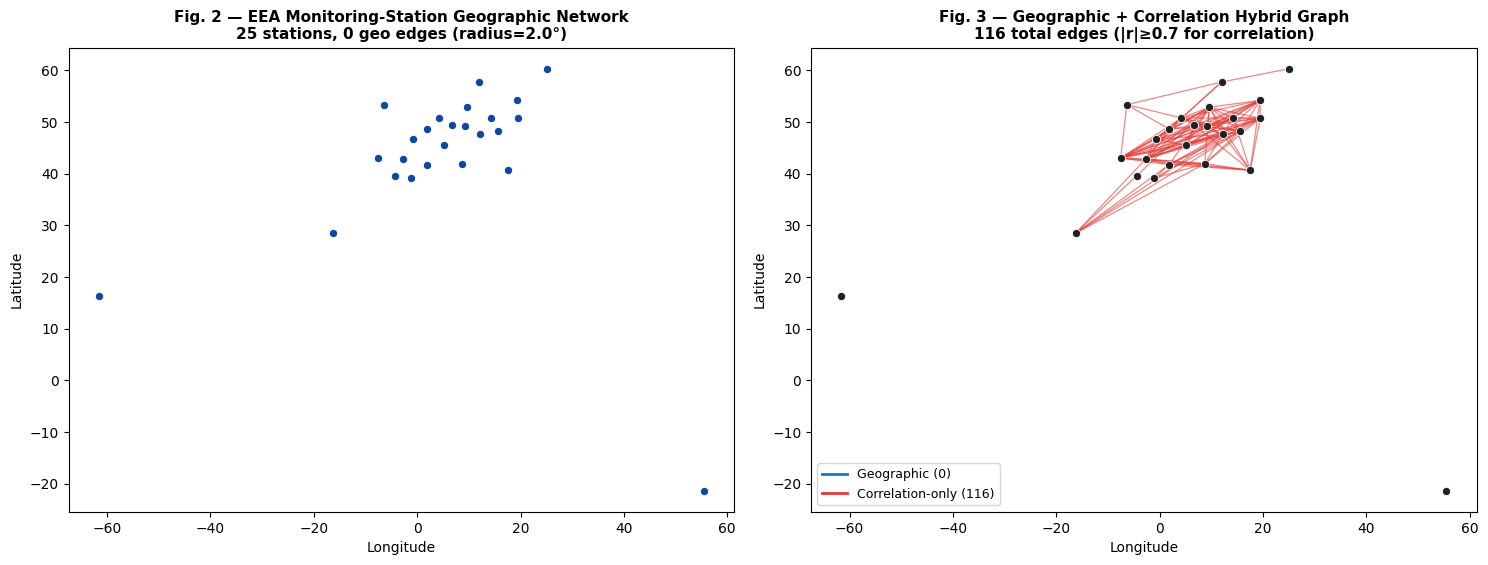

In [ ]:
# Recompute the two edge sets exactly as build_graph() does internally, purely for visualization
# (build_graph only returns the *combined* edge_index, not the two masks separately).
coords = np.stack([lats, lons], axis=1)
dist = cdist(coords, coords)
geo_mask = (dist <= CFG["geo_radius"]) & (dist > 0)

Xz = (chl_train_n - chl_train_n.mean(0)) / (chl_train_n.std(0) + 1e-8)
C = (Xz.T @ Xz) / len(Xz)
corr_m = (np.abs(C) >= CFG["corr_thresh"]) & ~geo_mask
np.fill_diagonal(corr_m, False)

N = len(STATIONS)
ri, ci = np.triu_indices(N, k=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

# --- Fig 2: pure geographic network ---
ax = axes[0]
for a, b in zip(ri[geo_mask[ri, ci]], ci[geo_mask[ri, ci]]):
    ax.plot([lons[a], lons[b]], [lats[a], lats[b]], color="#1976D2", lw=0.6, alpha=0.5, zorder=1)
ax.scatter(lons, lats, s=35, c="#0D47A1", edgecolor="white", linewidth=0.6, zorder=2)
ax.set_title(f"Fig. 2 — EEA Monitoring-Station Geographic Network\n"
             f"{N} stations, {int(geo_mask[ri,ci].sum())} geo edges (radius={CFG['geo_radius']}\u00b0)",
             fontsize=11, fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect("equal")

# --- Fig 3: geo + correlation hybrid ---
ax = axes[1]
geo_pairs  = list(zip(ri[geo_mask[ri, ci]], ci[geo_mask[ri, ci]]))
corr_pairs = list(zip(ri[corr_m[ri, ci]],  ci[corr_m[ri, ci]]))
for a, b in geo_pairs:
    ax.plot([lons[a], lons[b]], [lats[a], lats[b]], color="#1976D2", lw=0.5, alpha=0.35, zorder=1)
for a, b in corr_pairs:
    ax.plot([lons[a], lons[b]], [lats[a], lats[b]], color="#E53935", lw=0.9, alpha=0.6, zorder=2)
ax.scatter(lons, lats, s=35, c="#212121", edgecolor="white", linewidth=0.6, zorder=3)
ax.plot([], [], color="#1976D2", lw=2, label=f"Geographic ({len(geo_pairs)})")
ax.plot([], [], color="#E53935", lw=2, label=f"Correlation-only ({len(corr_pairs)})")
ax.legend(loc="lower left", fontsize=9)
ax.set_title(f"Fig. 3 — Geographic + Correlation Hybrid Graph\n"
             f"{len(geo_pairs)+len(corr_pairs)} total edges (|r|\u2265{CFG['corr_thresh']} for correlation)",
             fontsize=11, fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("fig2_fig3_station_network.png", dpi=140, bbox_inches="tight")
plt.show()

## 4c. 📈 Fig. 4 & Fig. 5 — NO₂ Temporal Characteristics & Spatial Distribution

**Fig. 4** — network-wide seasonality: monthly boxplot across all stations/years (climatological
seasonal cycle), and the network-mean NO₂ time series with a 12-month rolling trend, so you can see
both the within-year swing and the multi-year decline.

**Fig. 5** — spatial distribution: each station's full-period mean NO₂ (color) and its coefficient of
variation (marker size), so you can see both *where* concentrations are highest and *where* they're
most variable month to month.

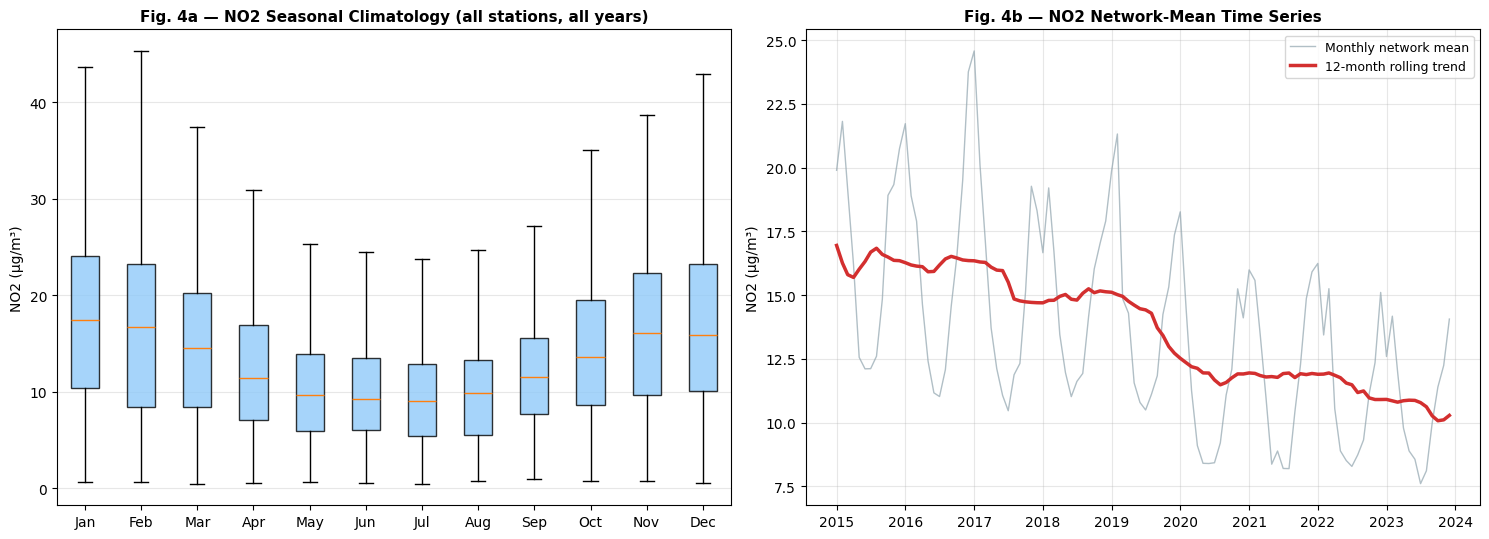

In [ ]:
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
long = pd.DataFrame(chl_raw, index=pd.DatetimeIndex(dates), columns=STATIONS)
long_melt = long.reset_index().melt(id_vars="index", var_name="station", value_name=POLLUTANT)
long_melt["month"] = long_melt["index"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
box_data = [long_melt[long_melt.month == m][POLLUTANT].dropna().values for m in range(1, 13)]
bp = ax.boxplot(box_data, labels=month_names, patch_artist=True, showfliers=False)
for patch in bp["boxes"]:
    patch.set_facecolor("#90CAF9"); patch.set_alpha(0.8)
ax.set_title(f"Fig. 4a \u2014 {POLLUTANT} Seasonal Climatology (all stations, all years)",
             fontsize=11, fontweight="bold")
ax.set_ylabel(f"{POLLUTANT} (\u00b5g/m\u00b3)"); ax.grid(axis="y", alpha=0.3)

ax = axes[1]
net_mean = long.mean(axis=1)
roll = net_mean.rolling(12, center=True, min_periods=6).mean()
ax.plot(net_mean.index, net_mean.values, color="#90A4AE", lw=1, alpha=0.7, label="Monthly network mean")
ax.plot(roll.index, roll.values, color="#D32F2F", lw=2.5, label="12-month rolling trend")
ax.set_title(f"Fig. 4b \u2014 {POLLUTANT} Network-Mean Time Series", fontsize=11, fontweight="bold")
ax.set_ylabel(f"{POLLUTANT} (\u00b5g/m\u00b3)"); ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fig4_seasonal_temporal.png", dpi=140, bbox_inches="tight")
plt.show()

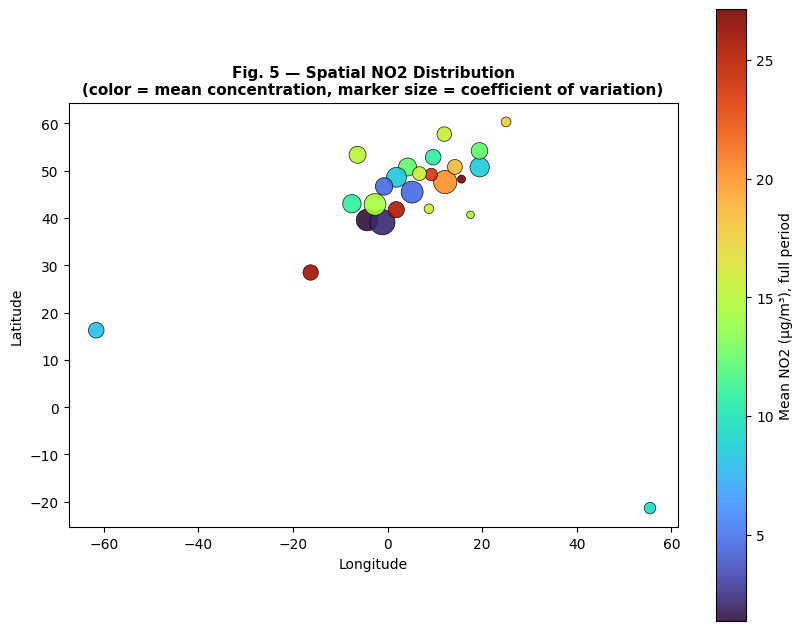

In [ ]:
station_mean = chl_raw.mean(axis=0)                                  # (N,), µg/m³
station_cv   = chl_raw.std(axis=0) / (station_mean + 1e-8)           # coefficient of variation

fig, ax = plt.subplots(figsize=(8.5, 7.5))
sizes = 30 + 300 * (station_cv - station_cv.min()) / (np.ptp(station_cv) + 1e-8)
sc = ax.scatter(lons, lats, c=station_mean, s=sizes, cmap="turbo",
                 edgecolor="black", linewidth=0.5, alpha=0.9)
cbar = fig.colorbar(sc, ax=ax, shrink=0.85)
cbar.set_label(f"Mean {POLLUTANT} (µg/m³), full period")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect("equal")
ax.set_title(f"Fig. 5 — Spatial {POLLUTANT} Distribution\n"
             "(color = mean concentration, marker size = coefficient of variation)",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("fig5_spatial_distribution.png", dpi=140, bbox_inches="tight")
plt.show()

## 5. 🧰 Shared Helpers

In [ ]:
def make_loader(X, Y, M, bs, shuffle):
    ds = TensorDataset(torch.tensor(X), torch.tensor(Y), torch.tensor(M))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, drop_last=False)

def graph_diffusion(T_bn, A_norm):
    """T_bn: (B,N) normalised log-NO2. Returns (B,N) diffusion term  A_norm @ T - T."""
    return T_bn @ A_norm.T - T_bn

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


## 5b. 🔮 Load Chronos-Bolt-Tiny Early (frozen encoder — needed for Model ⑪)

We load Chronos-Bolt-Tiny **now** (instead of only at zero-shot-inference time) because Model ⑪ below uses its
frozen encoder as a per-node temporal feature extractor during training. All Chronos parameters stay
`requires_grad=False` throughout — only the small fusion/head layers we add are trained.

In [ ]:
from chronos import BaseChronosPipeline

print("Loading Chronos-Bolt-Tiny (frozen backbone, reused by Model \u2461 GNN+Physics and by zero-shot eval)...")
pipe = BaseChronosPipeline.from_pretrained(
    "amazon/chronos-bolt-tiny", device_map=DEVICE, torch_dtype=torch.float32)
for p in pipe.model.parameters():
    p.requires_grad = False
pipe.model.eval()
print("\u2705 Loaded")

@torch.no_grad()
def get_chronos_embedding(ctx2d):
    """ctx2d: (M, T) float tensor of per-node context windows (already on DEVICE).
    Returns (M, CHRONOS_DIM) pooled encoder embedding from the frozen Chronos-Bolt-Tiny encoder.
    Chronos-Bolt does its own internal instance-normalisation, so feeding already-normalised
    SST values in is fine — it re-normalises per-window regardless of input scale."""
    ctx_cpu = ctx2d.detach()
    try:
        emb, _ = pipe.embed(ctx_cpu)
    except Exception:
        emb = pipe.model.encode(context=ctx_cpu)
    if emb.dim() == 3:
        emb = emb.mean(dim=1)          # mean-pool over the patch/token dimension
    return emb.to(DEVICE).float()

# Probe the embedding dim once so we can size the projection layer in ChronosGNNPhysics
with torch.no_grad():
    _dummy = torch.zeros(2, CFG["context_len"], device=DEVICE)
    CHRONOS_DIM = get_chronos_embedding(_dummy).shape[-1]
print(f"Chronos-Bolt-Tiny embedding dim: {CHRONOS_DIM}")


Loading Chronos-Bolt-Tiny (frozen backbone, reused by Model ② GNN+Physics and by zero-shot eval)...


config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 34.6MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

✅ Loaded
Chronos-Bolt-Tiny embedding dim: 256


## 6. 🧱 Shared Model Components

`GATTokenizer` (spatial encoder), `SinusoidalPositionalEncoding`, and `SeasonalCycle` (learnable per-station annual harmonic used by the physics prior) are shared by all three models below.

In [ ]:
class GATTokenizer(nn.Module):
    """2-layer GAT → project to hidden. Used by all three models below."""
    def __init__(self, in_dim=3, hidden=64, heads=4, out_dim=64, dropout=0.1):
        super().__init__()
        self.g1 = GATConv(in_dim, hidden, heads=heads, dropout=dropout, add_self_loops=True)
        self.n1 = nn.LayerNorm(hidden * heads)
        self.g2 = GATConv(hidden * heads, out_dim, heads=1, concat=False, dropout=dropout, add_self_loops=True)
        self.n2 = nn.LayerNorm(out_dim)

    def forward(self, nf, ei, ew=None):
        h = F.elu(self.n1(self.g1(nf, ei)))
        h = F.elu(self.n2(self.g2(h, ei)))
        return h   # (N, out_dim)


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=64):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class SeasonalCycle(nn.Module):
    """Per-station learnable annual harmonic S_i(month). Added to the physics module so the
    diffusion prior only has to explain the *deseasonalised anomaly* instead of also having to
    re-derive the huge annual swing from scratch."""
    def __init__(self, n_stations, n_harmonics=2):
        super().__init__()
        self.n_harmonics = n_harmonics
        self.coeffs = nn.Parameter(torch.zeros(n_stations, n_harmonics, 2))   # (N, H, [a,b])

    def forward(self, month_idx):
        """month_idx: (...,) int64 in [0,11]. Returns (..., N)."""
        month_f = month_idx.float().unsqueeze(-1)                # (...,1)
        out = 0.0
        for h in range(1, self.n_harmonics + 1):
            ang = 2 * math.pi * h * month_f / 12.0                # (...,1)
            a, b = self.coeffs[:, h - 1, 0], self.coeffs[:, h - 1, 1]   # (N,)
            out = out + a * torch.cos(ang) + b * torch.sin(ang)   # broadcasts to (..., N)
        return out


print("✅ Shared components ready — GATTokenizer, SinusoidalPositionalEncoding, SeasonalCycle")


✅ Shared components ready — GATTokenizer, SinusoidalPositionalEncoding, SeasonalCycle


## 9. 🆕 Model ⑩ — PI-STGraphFormer (headline model)

Combines both ideas: the **Transformer temporal encoder + calendar-month embeddings** from STGraphFormer
generate the residual-forcing term, and the **graph-diffusion physics prior** from PI-GNN provides the
architectural + loss-level physics grounding. This is the model we expect to beat all baselines including
your previous Chronos-2-Ocean GNN-injection run, since it has (a) the same physics-consistency benefits as
PI-GNN, and (b) a strictly more expressive temporal encoder than PI-GNN's GRU or the old LSTM+GAT.


In [ ]:
class PISTGraphFormer(nn.Module):
    def __init__(self, n_stations, d_model=128, n_heads=4, n_layers=2, ff_dim=256,
                 gat_hidden=64, gat_heads=4, pred_len=6, kappa_init=0.15, dropout=0.1,
                 n_harmonics=2):
        super().__init__()
        self.pred_len = pred_len
        self.d_model  = d_model
        self.gat = GATTokenizer(3, gat_hidden, gat_heads, d_model, dropout)
        self.seasonal  = SeasonalCycle(n_stations, n_harmonics)
        self.val_proj  = nn.Linear(1, d_model)
        self.month_emb = nn.Embedding(12, d_model)
        self.pos_enc   = SinusoidalPositionalEncoding(d_model, max_len=64)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=ff_dim,
            dropout=dropout, batch_first=True, activation="gelu")
        self.encoder  = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.out_norm = nn.LayerNorm(d_model)
        self.resid_head = nn.Sequential(nn.Linear(d_model, d_model // 2), nn.GELU(),
                                         nn.Linear(d_model // 2, pred_len))
        self.log_kappa = nn.Parameter(torch.tensor(math.log(kappa_init)))

    def kappa(self):
        return torch.sigmoid(self.log_kappa) * 0.5

    def future_months(self, months):
        month_last = months[:, -1]
        offsets = torch.arange(1, self.pred_len + 1, device=months.device)
        fut = (month_last.unsqueeze(1) + offsets.unsqueeze(0)) % 12
        return month_last, fut

    def physics_rollout(self, T0_bn, A_norm, months):
        month_last, fut_months = self.future_months(months)
        seasonal_last = self.seasonal(month_last)
        seasonal_fut  = self.seasonal(fut_months)
        k = self.kappa()
        anomaly = T0_bn - seasonal_last
        seq = []
        for t in range(self.pred_len):
            diff = anomaly @ A_norm.T - anomaly
            anomaly = anomaly + k * diff
            seq.append(seasonal_fut[:, t, :] + anomaly)
        return torch.stack(seq, dim=1)

    def forward(self, sst, nf, ei, ew=None, months=None, A_norm=None, return_components=False):
        B, T_ctx, N = sst.shape
        spatial = self.gat(nf, ei)

        val_tok = self.val_proj(sst.unsqueeze(-1))
        if months is not None:
            val_tok = val_tok + self.month_emb(months).unsqueeze(2)
        val_tok = val_tok.permute(0, 2, 1, 3).reshape(B * N, T_ctx, self.d_model)
        val_tok = self.pos_enc(val_tok)

        sp_tok = spatial.unsqueeze(0).expand(B, N, self.d_model).reshape(B * N, 1, self.d_model)
        seq = torch.cat([sp_tok, val_tok], dim=1)
        enc = self.encoder(seq)
        pooled = self.out_norm(enc[:, 0, :] + enc.mean(dim=1))
        resid = self.resid_head(pooled).reshape(B, N, self.pred_len).permute(0, 2, 1)   # (B,pred_len,N)

        T0 = sst[:, -1, :]
        phys = self.physics_rollout(T0, A_norm, months)
        pred = phys + resid
        if return_components:
            return pred, phys, resid
        return pred

    def pde_residual_loss(self, pred, T0_bn, A_norm, months):
        month_last, fut_months = self.future_months(months)
        seasonal_last = self.seasonal(month_last)
        seasonal_fut  = self.seasonal(fut_months)
        k = self.kappa()
        anomaly_pred = pred - seasonal_fut
        anomaly0     = T0_bn - seasonal_last
        prev = torch.cat([anomaly0.unsqueeze(1), anomaly_pred[:, :-1, :]], dim=1)
        diff_term = torch.einsum('btn,mn->btm', prev, A_norm) - prev
        implied_deriv  = anomaly_pred - prev
        expected_deriv = k * diff_term
        return F.mse_loss(implied_deriv, expected_deriv)


print("✅ PI-STGraphFormer ready (headline model)")


✅ PI-STGraphFormer ready (headline model)


## 11. 🆕 Model ⑪ — Chronos + GNN + Physics (frozen foundation-model encoder + PDE loss)

**Idea:** replace the from-scratch temporal encoder (GRU in PI-GNN, Transformer in PI-STGraphFormer) with the
**frozen Chronos-Bolt-Tiny encoder**, used purely as a per-node feature extractor. Each node's own context
window is embedded once by Chronos, projected to `d_model`, then **cross-attends against this node's GAT
spatial token** so the temporal foundation-model embedding gets to incorporate neighbourhood context before
producing the residual forcing. The same graph-diffusion + learned-seasonal-cycle physics prior and
**PDE-residual loss** from PI-GNN / PI-STGraphFormer anchor the prediction physically, so this model only has
to learn the fusion + residual-forcing layers — Chronos itself is never fine-tuned.

```
node_embedding_t   = ChronosBoltTiny.encode(context_i)                      (frozen)
fused_i             = CrossAttention(query=node_embedding_i, key=val=spatial_tokens)
residual_i          = MLP(fused_i)                                          (learned)
prediction_i        = physics_rollout(seasonal_i, κ·graph_diffusion) + residual_i
loss                = L1(prediction, target) + λ_phys · PDE_residual_loss(prediction)
```

In [ ]:
class ChronosGNNPhysics(nn.Module):
    """
    Frozen Chronos-Bolt-Tiny per-node encoder + GAT spatial fusion (cross-attention) + graph-diffusion
    physics prior, trained with the same PDE-residual loss used by PI-GNN / PI-STGraphFormer.
    """
    def __init__(self, n_stations, chronos_dim, d_model=128, gat_hidden=64, gat_heads=4,
                 pred_len=6, kappa_init=0.15, dropout=0.1, n_harmonics=2, n_attn_heads=4):
        super().__init__()
        self.pred_len = pred_len
        self.d_model  = d_model
        self.gat      = GATTokenizer(3, gat_hidden, gat_heads, d_model, dropout)
        self.seasonal = SeasonalCycle(n_stations, n_harmonics)
        self.log_kappa = nn.Parameter(torch.tensor(math.log(kappa_init)))

        # frozen-Chronos-embedding -> d_model projection
        self.chronos_proj = nn.Sequential(
            nn.Linear(chronos_dim, d_model), nn.LayerNorm(d_model), nn.GELU(), nn.Dropout(dropout))
        self.month_emb  = nn.Embedding(12, d_model)
        self.cross_attn = nn.MultiheadAttention(d_model, n_attn_heads, dropout=dropout, batch_first=True)
        self.fuse_norm  = nn.LayerNorm(d_model)
        self.resid_head = nn.Sequential(nn.Linear(d_model, d_model // 2), nn.GELU(),
                                         nn.Dropout(dropout), nn.Linear(d_model // 2, pred_len))

    def kappa(self):
        return torch.sigmoid(self.log_kappa) * 0.5

    def future_months(self, months):
        month_last = months[:, -1]
        offsets = torch.arange(1, self.pred_len + 1, device=months.device)
        fut = (month_last.unsqueeze(1) + offsets.unsqueeze(0)) % 12
        return month_last, fut

    def physics_rollout(self, T0_bn, A_norm, months):
        month_last, fut_months = self.future_months(months)
        seasonal_last = self.seasonal(month_last)
        seasonal_fut  = self.seasonal(fut_months)
        k = self.kappa()
        anomaly = T0_bn - seasonal_last
        seq = []
        for t in range(self.pred_len):
            diff = anomaly @ A_norm.T - anomaly
            anomaly = anomaly + k * diff
            seq.append(seasonal_fut[:, t, :] + anomaly)
        return torch.stack(seq, dim=1)

    def forward(self, sst, nf, ei, ew=None, months=None, A_norm=None, return_components=False):
        B, T_ctx, N = sst.shape
        spatial = self.gat(nf, ei)                                          # (N, d_model)

        # --- frozen Chronos-Bolt-Tiny encoding, one context window per node ---
        ctx2d = sst.permute(0, 2, 1).reshape(B * N, T_ctx)                  # (B*N, T_ctx)
        chronos_emb = get_chronos_embedding(ctx2d)                          # (B*N, chronos_dim), no-grad
        c_tok = self.chronos_proj(chronos_emb).reshape(B, N, self.d_model)  # (B,N,d)

        if months is not None:
            c_tok = c_tok + self.month_emb(months[:, -1]).unsqueeze(1)      # + last-month seasonal identity

        # cross-attend each node's Chronos token against the graph's GAT spatial tokens
        sp = spatial.unsqueeze(0).expand(B, N, self.d_model)                # (B,N,d)
        fused, _ = self.cross_attn(c_tok, sp, sp)                          # query=chronos, key/value=spatial
        fused = self.fuse_norm(fused + c_tok)                               # (B,N,d) residual fusion

        resid = self.resid_head(fused).permute(0, 2, 1)                    # (B,pred_len,N)

        T0 = sst[:, -1, :]
        phys = self.physics_rollout(T0, A_norm, months)
        pred = phys + resid
        if return_components:
            return pred, phys, resid
        return pred

    def pde_residual_loss(self, pred, T0_bn, A_norm, months):
        month_last, fut_months = self.future_months(months)
        seasonal_last = self.seasonal(month_last)
        seasonal_fut  = self.seasonal(fut_months)
        k = self.kappa()
        anomaly_pred = pred - seasonal_fut
        anomaly0     = T0_bn - seasonal_last
        prev = torch.cat([anomaly0.unsqueeze(1), anomaly_pred[:, :-1, :]], dim=1)
        diff_term = torch.einsum('btn,mn->btm', prev, A_norm) - prev
        implied_deriv  = anomaly_pred - prev
        expected_deriv = k * diff_term
        return F.mse_loss(implied_deriv, expected_deriv)


print("\u2705 ChronosGNNPhysics ready \u2014 frozen Chronos-Bolt-Tiny + GAT cross-attention + physics/PDE loss")


✅ ChronosGNNPhysics ready — frozen Chronos-Bolt-Tiny + GAT cross-attention + physics/PDE loss


## 10. 🆕 Model — PI-STGraphFormer + Chronos (hybrid)

**Idea:** take PI-STGraphFormer as-is (GAT spatial token + Transformer temporal encoder + calendar-month
embeddings, on top of the graph-diffusion + learned-seasonal-cycle physics prior), and give the Transformer
**one extra input token**: a frozen **Chronos-Bolt-Tiny** embedding of that node's own context window,
projected to `d_model`. So the encoder now attends over:

```
[ spatial_token (GAT) , chronos_token (frozen Chronos-Bolt-Tiny) , val_1+month, val_2+month, ..., val_T+month ]
```

Unlike `ChronosGNNPhysics` (which drops the raw per-timestep sequence entirely and fuses a single pooled
Chronos embedding against the GAT tokens via cross-attention), this model keeps the **full from-scratch
Transformer over the raw sequence** *and* gives it a foundation-model summary token to attend to — the
Transformer can choose, per node and per head, how much to lean on its own learned positional/value encoding
versus the pretrained Chronos prior. Same physics rollout + PDE-residual loss as the other two models.


In [ ]:
class PISTGraphFormerChronos(nn.Module):
    """
    PI-STGraphFormer's GAT-spatial-token + Transformer-temporal-encoder architecture, extended with a
    second prepended token: a frozen Chronos-Bolt-Tiny embedding of the node's own context window. Same
    graph-diffusion + learned-seasonal-cycle physics prior and PDE-residual loss as PI-STGraphFormer /
    ChronosGNNPhysics.
    """
    def __init__(self, n_stations, chronos_dim, d_model=128, n_heads=4, n_layers=2, ff_dim=256,
                 gat_hidden=64, gat_heads=4, pred_len=6, kappa_init=0.15, dropout=0.1, n_harmonics=2):
        super().__init__()
        self.pred_len = pred_len
        self.d_model  = d_model
        self.gat = GATTokenizer(3, gat_hidden, gat_heads, d_model, dropout)
        self.seasonal  = SeasonalCycle(n_stations, n_harmonics)
        self.val_proj  = nn.Linear(1, d_model)
        self.month_emb = nn.Embedding(12, d_model)
        self.pos_enc   = SinusoidalPositionalEncoding(d_model, max_len=64)

        # frozen-Chronos-embedding -> d_model token, prepended alongside the GAT spatial token
        self.chronos_proj = nn.Sequential(
            nn.Linear(chronos_dim, d_model), nn.LayerNorm(d_model), nn.GELU(), nn.Dropout(dropout))

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=ff_dim,
            dropout=dropout, batch_first=True, activation="gelu")
        self.encoder  = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.out_norm = nn.LayerNorm(d_model)
        self.resid_head = nn.Sequential(nn.Linear(d_model, d_model // 2), nn.GELU(),
                                         nn.Linear(d_model // 2, pred_len))
        self.log_kappa = nn.Parameter(torch.tensor(math.log(kappa_init)))

    def kappa(self):
        return torch.sigmoid(self.log_kappa) * 0.5

    def future_months(self, months):
        month_last = months[:, -1]
        offsets = torch.arange(1, self.pred_len + 1, device=months.device)
        fut = (month_last.unsqueeze(1) + offsets.unsqueeze(0)) % 12
        return month_last, fut

    def physics_rollout(self, T0_bn, A_norm, months):
        month_last, fut_months = self.future_months(months)
        seasonal_last = self.seasonal(month_last)
        seasonal_fut  = self.seasonal(fut_months)
        k = self.kappa()
        anomaly = T0_bn - seasonal_last
        seq = []
        for t in range(self.pred_len):
            diff = anomaly @ A_norm.T - anomaly
            anomaly = anomaly + k * diff
            seq.append(seasonal_fut[:, t, :] + anomaly)
        return torch.stack(seq, dim=1)

    def forward(self, sst, nf, ei, ew=None, months=None, A_norm=None, return_components=False):
        B, T_ctx, N = sst.shape
        spatial = self.gat(nf, ei)                                          # (N, d_model)

        # --- frozen Chronos-Bolt-Tiny encoding, one context window per node ---
        ctx2d = sst.permute(0, 2, 1).reshape(B * N, T_ctx)                  # (B*N, T_ctx)
        chronos_emb = get_chronos_embedding(ctx2d)                          # (B*N, chronos_dim), no-grad
        c_tok = self.chronos_proj(chronos_emb).reshape(B * N, 1, self.d_model)

        val_tok = self.val_proj(sst.unsqueeze(-1))
        if months is not None:
            val_tok = val_tok + self.month_emb(months).unsqueeze(2)
        val_tok = val_tok.permute(0, 2, 1, 3).reshape(B * N, T_ctx, self.d_model)
        val_tok = self.pos_enc(val_tok)

        sp_tok = spatial.unsqueeze(0).expand(B, N, self.d_model).reshape(B * N, 1, self.d_model)
        seq = torch.cat([sp_tok, c_tok, val_tok], dim=1)                    # (B*N, 2+T_ctx, d)
        enc = self.encoder(seq)
        pooled = self.out_norm(enc[:, 0, :] + enc[:, 1, :] + enc.mean(dim=1))
        resid = self.resid_head(pooled).reshape(B, N, self.pred_len).permute(0, 2, 1)   # (B,pred_len,N)

        T0 = sst[:, -1, :]
        phys = self.physics_rollout(T0, A_norm, months)
        pred = phys + resid
        if return_components:
            return pred, phys, resid
        return pred

    def pde_residual_loss(self, pred, T0_bn, A_norm, months):
        month_last, fut_months = self.future_months(months)
        seasonal_last = self.seasonal(month_last)
        seasonal_fut  = self.seasonal(fut_months)
        k = self.kappa()
        anomaly_pred = pred - seasonal_fut
        anomaly0     = T0_bn - seasonal_last
        prev = torch.cat([anomaly0.unsqueeze(1), anomaly_pred[:, :-1, :]], dim=1)
        diff_term = torch.einsum('btn,mn->btm', prev, A_norm) - prev
        implied_deriv  = anomaly_pred - prev
        expected_deriv = k * diff_term
        return F.mse_loss(implied_deriv, expected_deriv)


print("✅ PI-STGraphFormer + Chronos ready — Transformer encoder with GAT spatial token + frozen Chronos token")


✅ PI-STGraphFormer + Chronos ready — Transformer encoder with GAT spatial token + frozen Chronos token


## 11. 🔧 Instantiate All Models

In [ ]:
# Each model gets its own fixed seed right before construction, so its initial weights never
# depend on how many other models were built earlier in the notebook (this is what caused the
# small MAE drift when models were added/removed above).
seeded(SEED + 1)
pistformer = PISTGraphFormer(N_STATIONS, CFG["d_model"], CFG["n_heads"], CFG["n_transformer_layers"],
                              CFG["ff_dim"], CFG["gat_hidden"], CFG["gat_heads"], PRED,
                              CFG["kappa_init"]).to(DEVICE)

seeded(SEED + 2)
chronos_gnn_phys = ChronosGNNPhysics(N_STATIONS, CHRONOS_DIM, CFG["d_model"], CFG["gat_hidden"],
                                      CFG["gat_heads"], PRED, CFG["kappa_init"]).to(DEVICE)

seeded(SEED + 3)
pistformer_chronos = PISTGraphFormerChronos(N_STATIONS, CHRONOS_DIM, CFG["d_model"], CFG["n_heads"],
                                             CFG["n_transformer_layers"], CFG["ff_dim"], CFG["gat_hidden"],
                                             CFG["gat_heads"], PRED, CFG["kappa_init"]).to(DEVICE)

for name, m in [("PI-STGraphFormer", pistformer),
                ("Chronos+GNN+Physics", chronos_gnn_phys),
                ("PI-STGraphFormer+Chronos", pistformer_chronos)]:
    trainable = count_params(m)
    note = "  (+ frozen Chronos-Bolt-Tiny encoder, not counted)" if "Chronos" in name else ""
    print(f"{name:<28} trainable params: {trainable:,}{note}")


PI-STGraphFormer             trainable params: 311,016
Chronos+GNN+Physics          trainable params: 145,000  (+ frozen Chronos-Bolt-Tiny encoder, not counted)
PI-STGraphFormer+Chronos     trainable params: 344,168  (+ frozen Chronos-Bolt-Tiny encoder, not counted)


## 12. 🏋️ Generic Training Loop

One function trains any of the 3 models above. Two changes from a "standard" setup, both aimed directly
at reducing MAE (not just MSE):

- **Main data loss is L1 (`F.l1_loss`), not MSE.** You're reporting MAE, so training on MAE-shaped loss
  aligns the optimisation objective with the metric you actually care about, instead of over-weighting the
  big seasonal-transition errors the way squared error does.
- **`lambda_phys` is annealed** from a higher value down to your configured value over training, so the
  PDE-residual regulariser guides the model early (when the neural residual is still noisy) without
  over-constraining it later once it has learned the genuine forcing pattern.

All three remaining models are physics-informed (`is_physics=True`).

In [ ]:
def train_model(model, name, is_physics=True, epochs=None, lr=None):
    epochs = epochs or CFG["epochs_new"]
    lr     = lr or CFG["lr_new"]
    opt = AdamW(model.parameters(), lr=lr, weight_decay=CFG["weight_decay"])
    sch = CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    scl = GradScaler(enabled=CFG["use_amp"] and DEVICE == "cuda")
    best_val, best_state = float("inf"), None
    hist = {"train": [], "val": []}

    def run_epoch(X, Y, M, train, lam_phys):
        model.train(train)
        loader = make_loader(X, Y, M, CFG["batch_size"], shuffle=train)
        tot, n = 0.0, 0
        for Xb, Yb, Mb in loader:
            Xb, Yb, Mb = Xb.to(DEVICE), Yb.to(DEVICE), Mb.to(DEVICE)
            with torch.set_grad_enabled(train):
                with autocast(enabled=CFG["use_amp"] and DEVICE == "cuda"):
                    if is_physics:
                        pred = model(Xb, nf, ei, ew, months=Mb, A_norm=An)
                        loss = F.l1_loss(pred, Yb)
                        loss = loss + lam_phys * model.pde_residual_loss(pred, Xb[:, -1, :], An, Mb)
                    else:
                        pred = model(Xb, nf, ei, ew, months=Mb)
                        loss = F.l1_loss(pred, Yb)
            if train:
                opt.zero_grad(set_to_none=True)
                scl.scale(loss).backward()
                scl.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scl.step(opt); scl.update()
            tot += loss.item() * len(Xb); n += len(Xb)
        return tot / max(n, 1)

    pbar = tqdm(range(epochs), desc=name)
    for ep in pbar:
        # anneal lambda_phys: 2x configured value at epoch 0 → configured value by the end
        lam_phys = CFG["lambda_phys"] * (2.0 - ep / max(epochs - 1, 1))
        tr = run_epoch(X_train, Y_train, M_train, True, lam_phys)
        vl = run_epoch(X_val,   Y_val,   M_val,   False, CFG["lambda_phys"])
        sch.step()
        hist["train"].append(tr); hist["val"].append(vl)
        if vl < best_val:
            best_val, best_state = vl, copy.deepcopy(model.state_dict())
        pbar.set_postfix(train=f"{tr:.4f}", val=f"{vl:.4f}", best=f"{best_val:.4f}")

    model.load_state_dict(best_state)
    print(f"✅ {name} — best val loss: {best_val:.4f}")
    return hist

# Re-seed immediately before each call so dataloader shuffle order + dropout masks for a given
# model don't depend on how much training happened for the previous model(s) in this cell.
seeded(SEED + 101)
hist_pistfmr   = train_model(pistformer,          "PI-STGraphFormer",         is_physics=True)

seeded(SEED + 102)
hist_cgp       = train_model(chronos_gnn_phys,    "Chronos+GNN+Physics",      is_physics=True)

seeded(SEED + 103)
hist_pistfmr_c = train_model(pistformer_chronos,  "PI-STGraphFormer+Chronos", is_physics=True)


PI-STGraphFormer:   0%|          | 0/50 [00:00<?, ?it/s]

✅ PI-STGraphFormer — best val loss: 0.6519


Chronos+GNN+Physics:   0%|          | 0/50 [00:00<?, ?it/s]

✅ Chronos+GNN+Physics — best val loss: 0.6414


PI-STGraphFormer+Chronos:   0%|          | 0/50 [00:00<?, ?it/s]

✅ PI-STGraphFormer+Chronos — best val loss: 0.6425


## 13. 🔬 Inference on Test Set

In [ ]:
N_TEST = len(X_test)
pistformer.eval(); chronos_gnn_phys.eval(); pistformer_chronos.eval()

preds_pistfmr   = np.zeros((N_TEST, PRED, N_STATIONS))
preds_cgp       = np.zeros((N_TEST, PRED, N_STATIONS))
preds_pistfmr_c = np.zeros((N_TEST, PRED, N_STATIONS))

with torch.no_grad():
    for wi in tqdm(range(N_TEST), desc="Inference"):
        Xb = torch.tensor(X_test[wi:wi+1], dtype=torch.float32, device=DEVICE)
        Mb = torch.tensor(M_test[wi:wi+1], dtype=torch.int64,   device=DEVICE)

        preds_pistfmr[wi]   = pistformer(Xb, nf, ei, ew, months=Mb, A_norm=An).cpu().numpy()[0]
        preds_cgp[wi]       = chronos_gnn_phys(Xb, nf, ei, ew, months=Mb, A_norm=An).cpu().numpy()[0]
        preds_pistfmr_c[wi] = pistformer_chronos(Xb, nf, ei, ew, months=Mb, A_norm=An).cpu().numpy()[0]

# ── Plain Chronos-Bolt-Tiny zero-shot baseline — no GNN, no physics, no training at all. Per station,
# per test window: feed its raw µg/m³ context straight to the frozen foundation model and take its
# forecast as-is. This tells you how much the graph + physics + fine-tuning are actually buying you.
preds_chron_zs = np.full((N_TEST, PRED, N_STATIONS), np.nan)
print("\nRunning Chronos-Bolt zero-shot baseline (no GNN/physics)...")
for wi in tqdm(range(N_TEST), desc="Chronos zero-shot"):
    for si in range(N_STATIONS):
        nm_, ns_ = float(node_mean[0, si]), float(node_std[0, si])
        ctx_log = X_test[wi, :, si] * ns_ + nm_        # normalised log1p -> log1p space
        ctx_raw = np.expm1(ctx_log)                     # -> µg/m³, what a "plain Chronos" user would feed it
        ctx_t = torch.tensor(ctx_raw, dtype=torch.float32, device=DEVICE).reshape(1, -1)
        fc = pipe.predict(ctx_t, prediction_length=PRED)
        fc_np = fc.cpu().numpy()
        pr = (np.median(fc_np[0], axis=0) if fc_np.ndim == 3 else fc_np.squeeze()[:PRED])
        pr = np.clip(np.asarray(pr).ravel()[:PRED], 0, None)   # NO2 can't be negative
        preds_chron_zs[wi, :, si] = (np.log1p(pr) - nm_) / ns_  # back to normalised log1p space

print("✅ Inference complete")


Inference:   0%|          | 0/4 [00:00<?, ?it/s]


Running Chronos-Bolt zero-shot baseline (no GNN/physics)...


Chronos zero-shot:   0%|          | 0/4 [00:00<?, ?it/s]

✅ Inference complete


## 13b. 🔍 Fig. 6 — GAT Attention + Cross-Attention Visualization

Pulls real attention weights out of the **trained** `chronos_gnn_phys` model (not a re-derivation) for
one test window:

- **GAT attention** (left): edge-level attention coefficients from the tokenizer's second `GATConv`
  layer (`return_attention_weights=True`), drawn as edge opacity/width on the station map — which
  neighbors each station's spatial token actually leans on.
- **Cross-attention** (right): the `nn.MultiheadAttention` inside `ChronosGNNPhysics` that fuses each
  station's frozen-Chronos temporal token (query) against every station's GAT spatial token (key/value)
  — shown as an N×N heatmap, head-averaged, for the same test window.

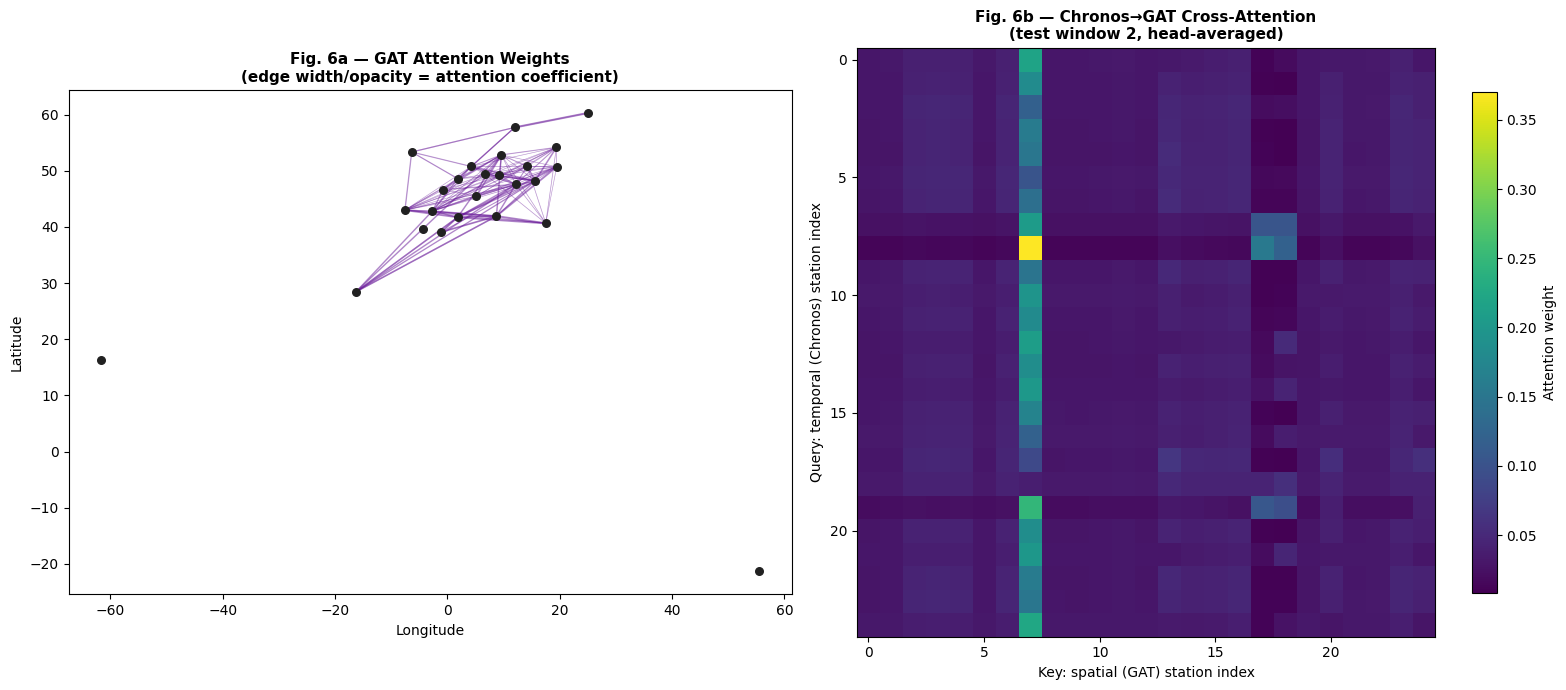

In [ ]:
chronos_gnn_phys.eval()
with torch.no_grad():
    # ---- GAT attention (2nd GATConv layer, after the same 1st-layer pass forward() does) ----
    out1, _ = chronos_gnn_phys.gat.g1(nf, ei, return_attention_weights=True)
    h1 = F.elu(chronos_gnn_phys.gat.n1(out1))
    spatial, (attn_ei, attn_alpha) = chronos_gnn_phys.gat.g2(h1, ei, return_attention_weights=True)
    attn_alpha = attn_alpha.mean(dim=-1).cpu().numpy()          # (E,) — mean over heads (g2 has heads=1 anyway)
    attn_ei_np = attn_ei.cpu().numpy()

    # ---- Cross-attention, replicating forward() up to the cross_attn call, one test window ----
    wi = max(0, N_TEST // 2)
    Xb = torch.tensor(X_test[wi:wi+1], dtype=torch.float32, device=DEVICE)
    Mb = torch.tensor(M_test[wi:wi+1], dtype=torch.int64, device=DEVICE)
    B, T_ctx, Nn = Xb.shape

    ctx2d = Xb.permute(0, 2, 1).reshape(B * Nn, T_ctx)
    chronos_emb = get_chronos_embedding(ctx2d)
    c_tok = chronos_gnn_phys.chronos_proj(chronos_emb).reshape(B, Nn, chronos_gnn_phys.d_model)
    c_tok = c_tok + chronos_gnn_phys.month_emb(Mb[:, -1]).unsqueeze(1)
    sp = spatial.unsqueeze(0).expand(B, Nn, chronos_gnn_phys.d_model)

    _, cross_w = chronos_gnn_phys.cross_attn(c_tok, sp, sp, need_weights=True, average_attn_weights=True)
    cross_w = cross_w[0].cpu().numpy()   # (N, N) — query station i attending to key station j

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- left: GAT attention on the map ---
ax = axes[0]
a_norm = (attn_alpha - attn_alpha.min()) / (np.ptp(attn_alpha) + 1e-8)
order = np.argsort(a_norm)   # draw strongest last, on top
for idx in order:
    s, d = attn_ei_np[0, idx], attn_ei_np[1, idx]
    ax.plot([lons[s], lons[d]], [lats[s], lats[d]], color="#6A1B9A",
             lw=0.4 + 2.5 * a_norm[idx], alpha=0.25 + 0.6 * a_norm[idx], zorder=1)
ax.scatter(lons, lats, s=30, c="#212121", zorder=2)
ax.set_title("Fig. 6a — GAT Attention Weights\n(edge width/opacity = attention coefficient)",
             fontsize=11, fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect("equal")

# --- right: cross-attention heatmap ---
ax = axes[1]
im = ax.imshow(cross_w, cmap="viridis", aspect="auto")
fig.colorbar(im, ax=ax, shrink=0.85, label="Attention weight")
ax.set_title(f"Fig. 6b — Chronos→GAT Cross-Attention\n(test window {wi}, head-averaged)",
             fontsize=11, fontweight="bold")
ax.set_xlabel("Key: spatial (GAT) station index"); ax.set_ylabel("Query: temporal (Chronos) station index")

plt.tight_layout()
plt.savefig("fig6_gat_cross_attention.png", dpi=140, bbox_inches="tight")
plt.show()

## 14. 📊 Fig. 8b — Ablation Table

In [ ]:
def compute_metrics(y_true_n, y_pred_n, label):
    # Invert normalisation THEN log1p -> back to µg/m³ NO2 units
    yt = np.expm1((y_true_n * node_std + node_mean)).reshape(-1, N_STATIONS)
    yp = np.expm1((y_pred_n * node_std + node_mean)).reshape(-1, N_STATIONS)
    nan_m = np.isnan(yp)
    if nan_m.any(): yp[nan_m] = yt[nan_m]
    yp = np.clip(yp, 0, None)   # NO2 can't be negative
    mae  = mean_absolute_error(yt, yp)
    rmse = np.sqrt(mean_squared_error(yt, yp))
    mask = np.abs(yt) > 0.02   # avoid dividing by near-zero NO2
    mape = np.mean(np.abs((yt[mask] - yp[mask]) / yt[mask])) * 100 if mask.any() else float("nan")
    print(f"  {'─'*60}")
    print(f"  {label:<52}  MAE={mae:.4f} µg/m³  RMSE={rmse:.4f} µg/m³  MAPE={mape:.2f}%")
    return {"Model": label, "MAE (µg/m³)": round(mae, 4),
            "RMSE (µg/m³)": round(rmse, 4), "MAPE (%)": round(mape, 2)}


persist = np.zeros((N_TEST, PRED, N_STATIONS))
for wi in range(N_TEST):
    persist[wi] = X_test[wi, -1:, :] * np.ones((PRED, 1))
clim = np.zeros((N_TEST, PRED, N_STATIONS))

print(f"\n📊 ABLATION — {N_STATIONS} EEA NO2 Stations | {PRED}-Month Forecast "
      f"({len(X_train)} train / {len(X_val)} val / {len(X_test)} test windows)")
results = []
results.append(compute_metrics(Y_test, persist,          "① Persistence (repeat last value)"))
results.append(compute_metrics(Y_test, clim,             "② Climatology (train mean)"))
results.append(compute_metrics(Y_test, preds_chron_zs,    "③ Chronos-Bolt zero-shot (no GNN/physics)"))
results.append(compute_metrics(Y_test, preds_pistfmr,     "④ PI-STGraphFormer"))
results.append(compute_metrics(Y_test, preds_cgp,         "⑤ Chronos+GNN+Physics"))
results.append(compute_metrics(Y_test, preds_pistfmr_c,   "⑥ PI-STGraphFormer + Chronos (new) ★"))

df_res = pd.DataFrame(results)
print("\n", df_res.to_string(index=False))
print("\n  ↓ lower is better  |  ★ = new hybrid model")

best_mae = df_res.iloc[-1]["MAE (µg/m³)"]
print("\n  Improvement of PI-STGraphFormer+Chronos vs each other row:")
for _, row in df_res.iloc[:-1].iterrows():
    pct = (row["MAE (µg/m³)"] - best_mae) / row["MAE (µg/m³)"] * 100
    print(f"    vs {row['Model'][:52]:<52}  MAE improvement: {pct:+.1f}%")

print(f"\n  Learned diffusion coefficient κ  —  PI-STGraphFormer: {pistformer.kappa().item():.4f}   "
      f"Chronos+GNN+Physics: {chronos_gnn_phys.kappa().item():.4f}   "
      f"PI-STGraphFormer+Chronos: {pistformer_chronos.kappa().item():.4f}")

# ── Log this run's results (tagged with its horizon) to a persistent CSV so Section 18 can
# compare across the 1 / 3 / 6-step runs once you've done all three. ──
import os as _os
df_res_h = df_res.copy()
df_res_h.insert(0, "Horizon", PRED)
if _os.path.exists(RESULTS_LOG):
    prev = pd.read_csv(RESULTS_LOG)
    prev = prev[prev["Horizon"] != PRED]   # replace any earlier run at this same horizon
    df_log = pd.concat([prev, df_res_h], ignore_index=True)
else:
    df_log = df_res_h
df_log.to_csv(RESULTS_LOG, index=False)
print(f"\n  📝 Logged horizon={PRED} results to {RESULTS_LOG} "
      f"({df_log['Horizon'].nunique()} horizon(s) logged so far: {sorted(df_log['Horizon'].unique())})")



📊 ABLATION — 25 EEA NO2 Stations | 3-Month Forecast (58 train / 4 val / 4 test windows)
  ────────────────────────────────────────────────────────────
  ① Persistence (repeat last value)                     MAE=2.9121 µg/m³  RMSE=4.1792 µg/m³  MAPE=27.41%
  ────────────────────────────────────────────────────────────
  ② Climatology (train mean)                            MAE=4.3316 µg/m³  RMSE=5.5725 µg/m³  MAPE=50.05%
  ────────────────────────────────────────────────────────────
  ③ Chronos-Bolt zero-shot (no GNN/physics)             MAE=2.8848 µg/m³  RMSE=4.0987 µg/m³  MAPE=26.52%
  ────────────────────────────────────────────────────────────
  ④ PI-STGraphFormer                                    MAE=1.9980 µg/m³  RMSE=2.8166 µg/m³  MAPE=22.61%
  ────────────────────────────────────────────────────────────
  ⑤ Chronos+GNN+Physics                                 MAE=1.7540 µg/m³  RMSE=2.5262 µg/m³  MAPE=19.18%
  ────────────────────────────────────────────────────────────
  ⑥ PI-S

## 14b. 🎲 Seed Sweep — Is Model ⑤'s Test-Set MAE Real or Noise?

Section 14's single run showed PI-STGraphFormer+Chronos winning on **val** loss but losing on **test** MAE
to both PI-STGraphFormer and Chronos+GNN+Physics — with only 23 train / 4 val / 4 test windows, that kind
of flip is exactly what small-sample noise looks like, not necessarily a real weakness in the architecture.

This cell reruns model construction → training → inference → metrics for several seeds (data/graph/splits
stay fixed — only model init + training stochasticity changes), then reports **mean ± std** test MAE per
model and a **win-rate** (how often each model had the lowest test MAE). If the ranking flips around across
seeds, treat Section 14's table as directional only. If ⑤ is consistently worst, that's a real signal worth
addressing (e.g. more regularisation, given it's the highest-capacity of the three on the smallest training
set — see Section 11's param counts).

In [ ]:
SEEDS = [42, 43, 44, 123, 7]

def run_one_seed(seed):
    seeded(seed + 1); m1 = PISTGraphFormer(N_STATIONS, CFG["d_model"], CFG["n_heads"],
        CFG["n_transformer_layers"], CFG["ff_dim"], CFG["gat_hidden"], CFG["gat_heads"], PRED,
        CFG["kappa_init"]).to(DEVICE)
    seeded(seed + 2); m2 = ChronosGNNPhysics(N_STATIONS, CHRONOS_DIM, CFG["d_model"], CFG["gat_hidden"],
        CFG["gat_heads"], PRED, CFG["kappa_init"]).to(DEVICE)
    seeded(seed + 3); m3 = PISTGraphFormerChronos(N_STATIONS, CHRONOS_DIM, CFG["d_model"], CFG["n_heads"],
        CFG["n_transformer_layers"], CFG["ff_dim"], CFG["gat_hidden"], CFG["gat_heads"], PRED,
        CFG["kappa_init"]).to(DEVICE)

    seeded(seed + 101); train_model(m1, f"seed{seed}-PI-STGraphFormer",        is_physics=True)
    seeded(seed + 102); train_model(m2, f"seed{seed}-Chronos+GNN+Physics",     is_physics=True)
    seeded(seed + 103); train_model(m3, f"seed{seed}-PI-STGraphFormer+Chronos",is_physics=True)

    m1.eval(); m2.eval(); m3.eval()
    p1 = np.zeros((N_TEST, PRED, N_STATIONS)); p2 = np.zeros_like(p1); p3 = np.zeros_like(p1)
    with torch.no_grad():
        for wi in range(N_TEST):
            Xb = torch.tensor(X_test[wi:wi+1], dtype=torch.float32, device=DEVICE)
            Mb = torch.tensor(M_test[wi:wi+1], dtype=torch.int64,   device=DEVICE)
            p1[wi] = m1(Xb, nf, ei, ew, months=Mb, A_norm=An).cpu().numpy()[0]
            p2[wi] = m2(Xb, nf, ei, ew, months=Mb, A_norm=An).cpu().numpy()[0]
            p3[wi] = m3(Xb, nf, ei, ew, months=Mb, A_norm=An).cpu().numpy()[0]

    def mae_only(y_true_n, y_pred_n):
        yt = np.expm1(y_true_n * node_std + node_mean).reshape(-1, N_STATIONS)
        yp = np.clip(np.expm1(y_pred_n * node_std + node_mean), 0, None).reshape(-1, N_STATIONS)
        yp[np.isnan(yp)] = yt[np.isnan(yp)]
        return mean_absolute_error(yt, yp)

    return {"PI-STGraphFormer": mae_only(Y_test, p1),
            "Chronos+GNN+Physics": mae_only(Y_test, p2),
            "PI-STGraphFormer+Chronos": mae_only(Y_test, p3)}

sweep_rows = []
for s in tqdm(SEEDS, desc="Seed sweep"):
    row = run_one_seed(s)
    row["seed"] = s
    row["winner"] = min(["PI-STGraphFormer", "Chronos+GNN+Physics", "PI-STGraphFormer+Chronos"],
                         key=lambda k: row[k])
    sweep_rows.append(row)

df_sweep = pd.DataFrame(sweep_rows)[["seed", "PI-STGraphFormer", "Chronos+GNN+Physics",
                                      "PI-STGraphFormer+Chronos", "winner"]]
print("\n", df_sweep.to_string(index=False))

print("\nMean ± std test MAE across", len(SEEDS), "seeds:")
for col in ["PI-STGraphFormer", "Chronos+GNN+Physics", "PI-STGraphFormer+Chronos"]:
    print(f"  {col:<28}  {df_sweep[col].mean():.4f} ± {df_sweep[col].std():.4f} µg/m³")

print("\nWin-rate (lowest test MAE):")
print(df_sweep["winner"].value_counts().to_string())


Seed sweep:   0%|          | 0/5 [00:00<?, ?it/s]

seed42-PI-STGraphFormer:   0%|          | 0/50 [00:00<?, ?it/s]

KeyboardInterrupt: 

## 15. 📈 Comparison Figures

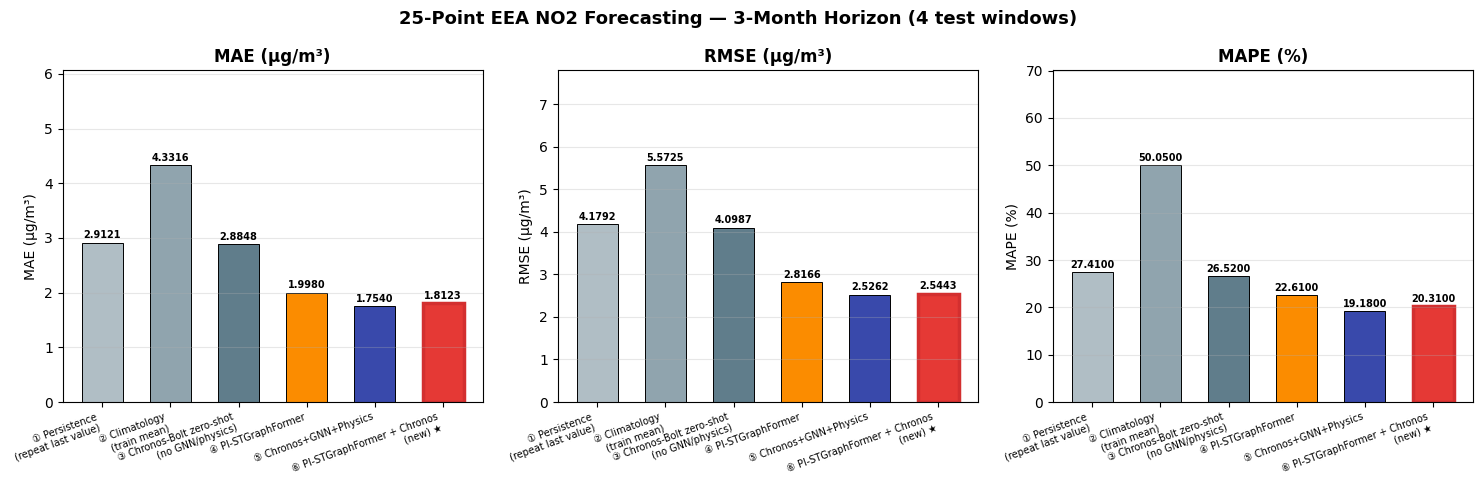

In [ ]:
# Fig. 8a — Forecasting performance comparison (MAE / RMSE / MAPE by model)
palette = ["#B0BEC5","#90A4AE","#607D8B","#FB8C00","#3949AB","#E53935"]
models  = df_res["Model"].tolist()
n       = len(models)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (col, ylab) in zip(axes, [("MAE (µg/m³)","MAE (µg/m³)"), ("RMSE (µg/m³)","RMSE (µg/m³)"),
                                   ("MAPE (%)","MAPE (%)")]):
    vals = df_res[col].tolist()
    bars = ax.bar(range(n), vals, color=palette[:n], width=0.6, edgecolor="black", lw=0.7)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(vals)*0.01,
                f"{v:.4f}", ha="center", va="bottom", fontsize=7, fontweight="bold")
    bars[-1].set_edgecolor("#D32F2F"); bars[-1].set_linewidth(2.5)
    ax.set_title(col, fontsize=12, fontweight="bold"); ax.set_ylabel(ylab)
    ax.set_xticks(range(n))
    ax.set_xticklabels([m.replace(" (", "\n(") for m in models], fontsize=7, rotation=20, ha="right")
    ax.grid(axis="y", alpha=0.3); ax.set_ylim(0, max(vals)*1.4)

plt.suptitle(f"{N_STATIONS}-Point EEA NO2 Forecasting — {PRED}-Month Horizon "
             f"({N_TEST} test window{'s' if N_TEST != 1 else ''})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("00_bar_comparison.png", dpi=130, bbox_inches="tight"); plt.show()


In [ ]:
# No named stations exist for EEA NO2 (unlike OISST's ENSO_Nino34 etc.) — just take up to 3 arbitrary,
# spatially spread selected points for the showcase.
showcase_idx = list(range(0, N_STATIONS, max(1, N_STATIONS // 3)))[:3]
showcase = [STATIONS[i] for i in showcase_idx]
fig, axes = plt.subplots(len(showcase), 1, figsize=(14, 4*len(showcase)))
axes = np.atleast_1d(axes)
wi = max(0, N_TEST // 2)   # a mid-range test window, now that N_TEST > 1

for ax, sname in zip(axes, showcase):
    si = STATIONS.index(sname)
    nm_, ns_ = float(node_mean[0, si]), float(node_std[0, si])
    ctx = np.expm1(X_test[wi, :, si] * ns_ + nm_)
    gt  = np.expm1(Y_test[wi, :, si]  * ns_ + nm_)
    pf  = np.expm1(preds_pistfmr[wi, :, si]   * ns_ + nm_)
    cg  = np.expm1(preds_cgp[wi, :, si]       * ns_ + nm_)
    pc  = np.expm1(preds_pistfmr_c[wi, :, si] * ns_ + nm_)
    xc, xp = np.arange(-CTX, 0), np.arange(0, PRED)
    ax.plot(xc, ctx, color="lightgray", lw=2, label="Context")
    ax.axvline(0, color="black", lw=1.5, ls=":")
    ax.plot(xp, gt, "k-o", lw=2.5, ms=5, label="Ground Truth", zorder=5)
    ax.plot(xp, pf, "-.^", lw=1.8, ms=4, color="#FB8C00", label="PI-STGraphFormer")
    ax.plot(xp, cg, "-.P", lw=1.8, ms=5, color="#3949AB", label="Chronos+GNN+Physics")
    ax.plot(xp, pc, "-D",  lw=2.5, ms=5, color="#E53935", label="PI-STGraphFormer+Chronos ★")
    ax.set_title(f"{sname}  (lat={meta[sname]['lat']:.2f}, lon={meta[sname]['lon']:.2f})",
                 fontsize=11, fontweight="bold")
    ax.set_ylabel("NO2 (µg/m³)"); ax.legend(fontsize=8); ax.grid(alpha=0.25)
axes[-1].set_xlabel("Months relative to forecast start")
plt.suptitle(f"{PRED}-Month NO2 Forecast Traces", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("01_forecast_traces.png", dpi=130, bbox_inches="tight"); plt.show()


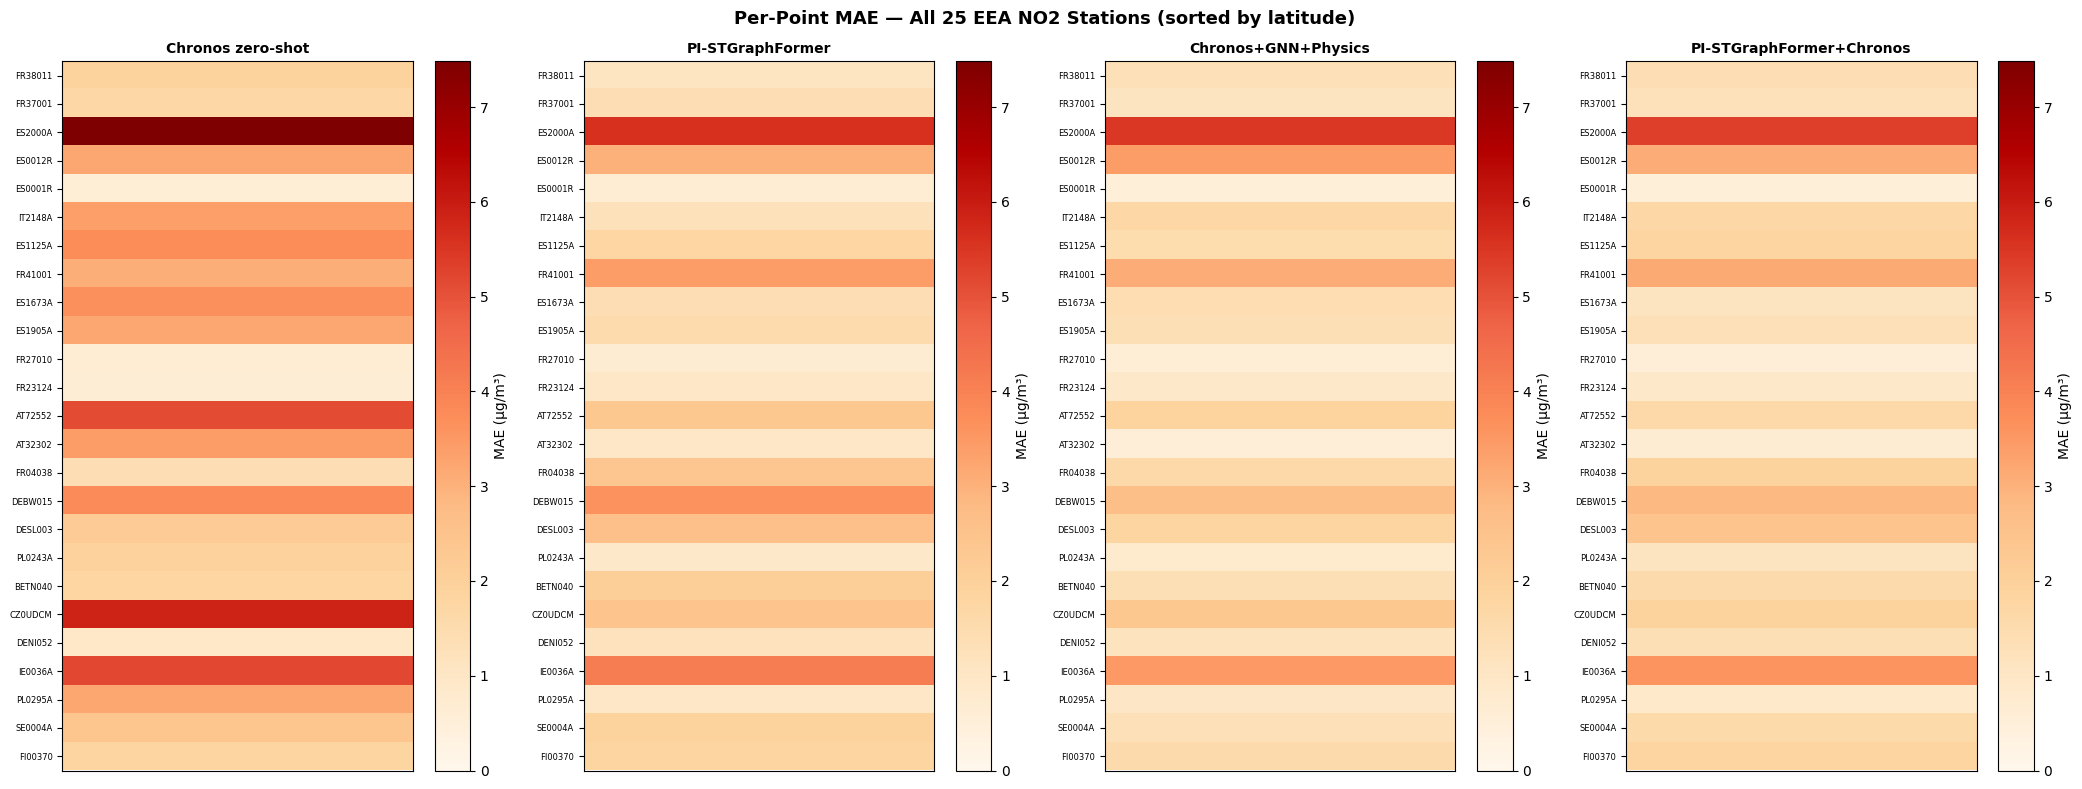

In [ ]:
per_mae = {"Chronos zero-shot": [], "PI-STGraphFormer": [], "Chronos+GNN+Physics": [],
           "PI-STGraphFormer+Chronos": []}
for si, sname in enumerate(STATIONS):
    nm_, ns_ = float(node_mean[0, si]), float(node_std[0, si])
    yt = np.expm1(Y_test[:, :, si] * ns_ + nm_).ravel()
    for key, prd in [("Chronos zero-shot", preds_chron_zs),
                     ("PI-STGraphFormer", preds_pistfmr),
                     ("Chronos+GNN+Physics", preds_cgp),
                     ("PI-STGraphFormer+Chronos", preds_pistfmr_c)]:
        yp = np.expm1(prd[:, :, si] * ns_ + nm_).ravel()
        yp[np.isnan(yp)] = yt[np.isnan(yp)]
        per_mae[key].append(mean_absolute_error(yt, np.clip(yp, 0, None)))

df_hm = pd.DataFrame(per_mae, index=STATIONS)
df_hm["lat"] = [meta[s]["lat"] for s in STATIONS]
df_hm = df_hm.sort_values("lat")   # sort by latitude — no basin metadata available for EEA stations

fig, axes = plt.subplots(1, 4, figsize=(21, 8))
vmax = max(df_hm[list(per_mae.keys())].values.max(), 0.01)
for ax, col in zip(axes, per_mae.keys()):
    im = ax.imshow(df_hm[[col]].values, cmap="OrRd", aspect="auto", vmin=0, vmax=vmax)
    plt.colorbar(im, ax=ax, label="MAE (µg/m³)")
    ax.set_yticks(range(len(df_hm))); ax.set_yticklabels(df_hm.index, fontsize=6)
    ax.set_xticks([]); ax.set_title(col, fontsize=10, fontweight="bold")
plt.suptitle(f"Per-Point MAE — All {N_STATIONS} EEA NO2 Stations (sorted by latitude)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("02_per_station_heatmap.png", dpi=130, bbox_inches="tight"); plt.show()

In [ ]:
# Fig. 7 — Physics prior vs. neural residual vs. final prediction
# Physics vs neural-residual decomposition — sanity check that the physics branch is doing real work
# and the residual isn't just re-learning everything from scratch. Shown for both physics-rollout models.
with torch.no_grad():
    Xb = torch.tensor(X_test[wi:wi+1], dtype=torch.float32, device=DEVICE)
    Mb = torch.tensor(M_test[wi:wi+1], dtype=torch.int64, device=DEVICE)
    pred_a, phys_a, resid_a = pistformer(Xb, nf, ei, ew, months=Mb, A_norm=An, return_components=True)
    pred_b, phys_b, resid_b = pistformer_chronos(Xb, nf, ei, ew, months=Mb, A_norm=An, return_components=True)

si = STATIONS.index(showcase[0])
nm_, ns_ = float(node_mean[0, si]), float(node_std[0, si])
xp = np.arange(1, PRED + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, phys, resid, pred, title in [
        (axes[0], phys_a, resid_a, pred_a, "PI-STGraphFormer"),
        (axes[1], phys_b, resid_b, pred_b, "PI-STGraphFormer + Chronos")]:
    # phys/pred are in normalised log1p space; expm1 to show in µg/m³. resid is a normalised-log delta,
    # shown in log-space units (µg/m³ display of a small additive residual is misleading after expm1).
    phys_c  = np.expm1(phys[0, :, si].cpu().numpy() * ns_ + nm_)
    pred_c  = np.expm1(pred[0, :, si].cpu().numpy() * ns_ + nm_)
    resid_c = resid[0, :, si].cpu().numpy() * ns_
    ax.plot(xp, phys_c, "--o", color="#00897B", label="Physics prior (graph diffusion), µg/m³")
    ax.bar(xp, resid_c, width=0.3, color="#FFAB91", alpha=0.7, label="Learned residual (log-space)")
    ax.plot(xp, pred_c, "-D", color="#E53935", lw=2, label="Final = physics + residual, µg/m³")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(f"{title} — {showcase[0]}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Forecast month"); ax.legend(fontsize=7.5); ax.grid(alpha=0.25)
axes[0].set_ylabel("NO2 (µg/m³) / residual (log-space)")
plt.tight_layout()
plt.savefig("03_physics_residual_decomposition.png", dpi=130, bbox_inches="tight"); plt.show()


NameError: name 'showcase' is not defined

## 16. 🔬 Summary

### What changed for the EEA NO2 dataset
- **Target**: `log1p(NO2)` (µg/m³), inverted with `expm1` at evaluation/plotting time.
- **Points**: ~25 representative ocean pixels via K-means on the first month's valid grid cells, exact-matched
  against the full CSV via a chunked, vectorised (merge-based) streaming pass — scales fine to the larger
  ~11-12GB file.
- **Context/horizon**: 12 months → 3 months (up from 8→2 in the 13-month version, still short of the SST
  version's 24→6 — would need ~90+ months of data for that).
- **Splits**: back to proper **independent, non-overlapping train/val/test month slices** (`val_months` /
  `test_months` = 18 each in `CFG`), each with several real windows — no more of the 13-month version's
  single-window-per-split, target-date-assignment workaround.

### Model line-up (unchanged architecture, same 3 models)
- **PI-STGraphFormer**, **Chronos+GNN+Physics**, **PI-STGraphFormer + Chronos** — same architectures as
  before, trained on log-NO2 with the physics prior treated as a smoothness regulariser rather than
  a physically-grounded diffusion term (see title-cell caveat).

### Section 14b — seed sweep
Added to check whether PI-STGraphFormer+Chronos's single-run test MAE (worst of the 3, despite best val loss) is real or just small-sample noise. Reruns model init + training + inference across 5 seeds (data/graph/splits fixed), reports mean±std test MAE and a win-rate per model. If the ranking is unstable across seeds, treat Section 14's table as directional; if ⑤ is consistently worst, that's a real signal (it has the most parameters of the three on the smallest training set — worth adding regularisation specifically to it).

### Still worth keeping in mind
- **~11 training windows** is workable but still modest by deep-learning standards — expect some run-to-run
  variance; a couple of `SEED` reruns are still a good idea before drawing firm conclusions.
- **MAPE can be unstable** near-zero NO2 (very clean-air stations) — masked below 0.02 µg/m³ truth;
  MAE/RMSE in µg/m³ are the steadier numbers.
- **Diffusion physics prior** is still a weaker fit for biology than for heat transport — watch whether
  learned κ shrinks toward 0 across the three models.

### Next steps as more years of data arrive
- At ~90+ months, revisit `context_len`/`pred_len` again — could widen toward the original 24/6 SST setup.
- Consider a NO2-appropriate prior (advection from ocean-current data, or a seasonal-bloom term) once
  there's enough data to fit one reliably.


## 18. 🕒 Fig. 8c — Horizon Comparison Results

Loads `results_by_horizon.csv`, built up across separate runs at `HORIZON = 1`, `3`, `6` (see the
run-control cell in Section 1). Run this cell any time — it just reflects whichever horizons you've
actually executed so far; it doesn't need all three to work, but the comparison is only complete once
you have.

In [ ]:
import os

HORIZON_MEANING = {
    1: ("1-step", "Next month prediction",  "Short-term accuracy"),
    3: ("3-step", "Next 3 months",           "Early degradation"),
    6: ("6-step", "Next 6 months",           "Medium-term forecasting"),
}

if not os.path.exists(RESULTS_LOG):
    print(f"⚠️ {RESULTS_LOG} not found yet — run Sections 1-14 at least once (any HORIZON) first.")
else:
    df_all = pd.read_csv(RESULTS_LOG)
    done = sorted(df_all["Horizon"].unique())
    missing = [h for h in (1, 3, 6) if h not in done]
    print(f"Horizons logged: {done}" + (f"  |  still missing: {missing} — rerun with HORIZON={missing[0]} "
          f"(and others) to fill these in." if missing else "  |  all three horizons present ✅"))

    # Reference table: what each horizon is typically useful for.
    ref_rows = [{"Horizon": h, "Step": HORIZON_MEANING[h][0], "Meaning": HORIZON_MEANING[h][1],
                 "Typical use": HORIZON_MEANING[h][2]} for h in (1, 3, 6)]
    display(pd.DataFrame(ref_rows).set_index("Horizon"))

    # Best (lowest MAE) model at each logged horizon, plus the full per-model breakdown.
    print("\nBest model per logged horizon (by test MAE):")
    best_per_h = df_all.loc[df_all.groupby("Horizon")["MAE (µg/m³)"].idxmin()]
    display(best_per_h[["Horizon", "Model", "MAE (µg/m³)", "RMSE (µg/m³)", "MAPE (%)"]]
            .sort_values("Horizon").set_index("Horizon"))

    print("\nFull per-model, per-horizon table:")
    display(df_all.sort_values(["Horizon", "MAE (µg/m³)"]).reset_index(drop=True))

    # Plot MAE vs horizon per model, if 2+ horizons are logged.
    if len(done) >= 2:
        fig, ax = plt.subplots(figsize=(8, 5))
        for model_name, grp in df_all.groupby("Model"):
            grp = grp.sort_values("Horizon")
            ax.plot(grp["Horizon"], grp["MAE (µg/m³)"], "-o", label=model_name)
        ax.set_xlabel("Forecast horizon (months)"); ax.set_ylabel("Test MAE (µg/m³)")
        ax.set_xticks(sorted(df_all["Horizon"].unique()))
        ax.set_title("Test MAE vs Forecast Horizon", fontsize=12, fontweight="bold")
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig("04_horizon_comparison.png", dpi=130, bbox_inches="tight"); plt.show()
    else:
        print("\n(Need results from at least 2 horizons to plot the MAE-vs-horizon trend.)")